Johan Camilo Balanta Santacruz - 30000115778
Delio Fernando Palacios Viafara - 30000115782

# Identificación de enfermedades en hojas de plantas
Este notebook entrena un modelo de clasificación de imágenes con el dataset PlantVillage usando TensorFlow/Keras.



## 1. Importar las librerías necesarias

Todas las herramientas que vamos a usar: pandas y numpy para datos, matplotlib para gráficos, TensorFlow para el modelo, sklearn para separar datos.

In [3]:
import kagglehub
import os

import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import pandas as pd

import tensorflow as tf
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from tensorflow.keras import layers, models, optimizers
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
from sklearn.model_selection import train_test_split

## 2. Descargar el dataset de plantas

Bajamos 70,000 imágenes de hojas sanas y enfermas (tomate, papa, pimiento) desde Kaggle Hub.

In [4]:
# Descarga el dataset PlantDisease desde KaggleHub
path = kagglehub.dataset_download("emmarex/plantdisease")

Using Colab cache for faster access to the 'plantdisease' dataset.


In [5]:
import os

data_dir = os.path.join(path, "PlantVillage")

if not os.path.isdir(data_dir):
    raise FileNotFoundError(
        f"No se encontró el directorio: {data_dir}. "
        f"Contenido: {os.listdir(path)[:10]}"
    )

print("Directorio de datos:", data_dir)


Directorio de datos: /kaggle/input/plantdisease/PlantVillage


## 3. Preparación y validación de imágenes

Filtramos solo imágenes válidas (.jpg, .png) y las que no estén dañadas. Descartamos las corruptas para evitar errores en el entrenamiento.

In [6]:
# Verificamos la cantidad de clases que maneja el dataset
classes = os.listdir(data_dir)
print("Total clases:", len(classes))
print(classes[:10])


Total clases: 15
['Pepper__bell___Bacterial_spot', 'Potato___healthy', 'Tomato_Leaf_Mold', 'Tomato__Tomato_YellowLeaf__Curl_Virus', 'Tomato_Bacterial_spot', 'Tomato_Septoria_leaf_spot', 'Tomato_healthy', 'Tomato_Spider_mites_Two_spotted_spider_mite', 'Tomato_Early_blight', 'Tomato__Target_Spot']


In [7]:
# Recorremos clases y filtramos solo imágenes válidas

file_paths = []
labels = []

valid_ext = (".jpg", ".jpeg", ".png")
invalid_count = 0

for clase in os.listdir(data_dir):
    folder = os.path.join(data_dir, clase)
    if not os.path.isdir(folder):
        continue

    for img_name in os.listdir(folder):
        if not img_name.lower().endswith(valid_ext):
            continue

        img_path = os.path.join(folder, img_name)
        if not os.path.isfile(img_path) or os.path.getsize(img_path) == 0:
            invalid_count += 1
            continue

        try:
            with Image.open(img_path) as im:
                im.verify()
        except Exception:
            invalid_count += 1
            continue

        file_paths.append(img_path)
        labels.append(clase)

print("Imágenes válidas encontradas:", len(file_paths))
print("Imágenes inválidas descartadas:", invalid_count)

Imágenes válidas encontradas: 20638
Imágenes inválidas descartadas: 0


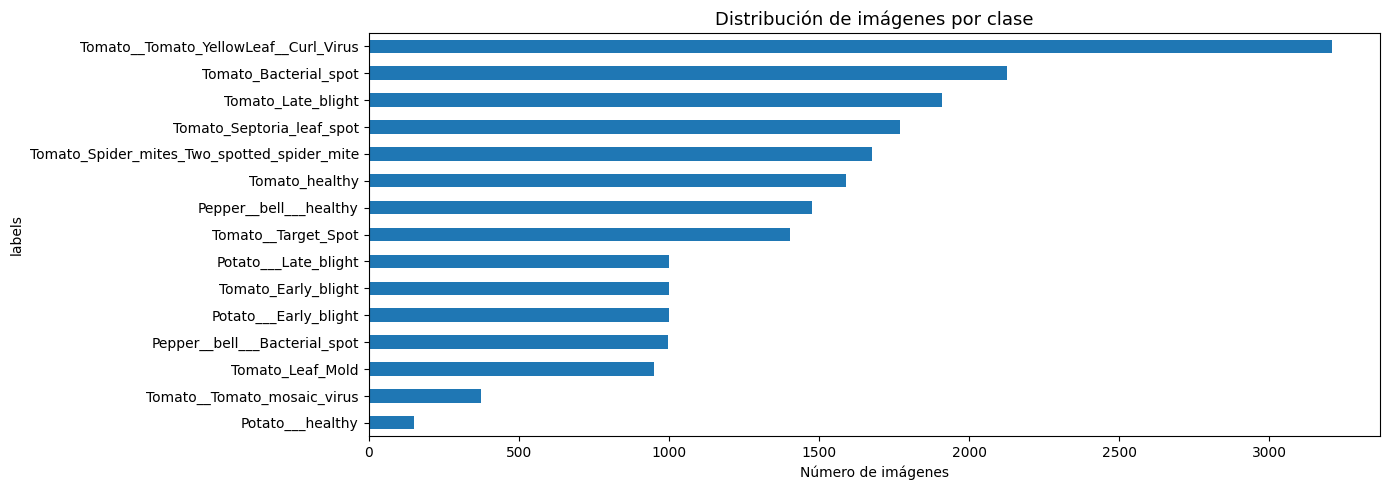


Estadísticas de cantidad de imágenes por clase:
count      15.0
mean     1375.9
std       744.5
min       152.0
25%       998.5
50%      1404.0
75%      1723.5
max      3208.0
Name: count, dtype: float64


In [25]:
df = pd.DataFrame({"file_paths": file_paths, "labels": labels})

# ── Distribución de clases ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(14, 5))
counts = df["labels"].value_counts().sort_values()
counts.plot(kind="barh", ax=ax)
ax.set_title("Distribución de imágenes por clase", fontsize=13)
ax.set_xlabel("Número de imágenes")
plt.tight_layout()
plt.show()

print("\nEstadísticas de cantidad de imágenes por clase:")
print(df["labels"].value_counts().describe().round(1))

## 4. Convertir a números, balancear y dividir datos

Convertimos nombres a números con LabelEncoder (Tomato_healthy → 0). Luego balanceamos: clases con pocas imágenes se duplican a ~300. Finalmente dividimos: 60% entrena, 20% valida, 20% prueba.

In [26]:
# --- Encode primero para convertir las etiquetas a números ---
le = LabelEncoder()
df['labels'] = le.fit_transform(df['labels'])
NUM_CLASSES = len(le.classes_)

# --- Dividimos PRIMERO para evitar contaminación entre conjuntos ---
df_temp, df_test = train_test_split(df, test_size=0.2, random_state=40, stratify=df["labels"])
df_train, df_val = train_test_split(df_temp, test_size=0.2, random_state=40, stratify=df_temp["labels"])

# --- Oversampling para beneficiar a las clases con menor cantidad de datos ---
def oversample_to_minimum(df, label_col='labels', min_samples=300):
    grupos = []
    for clase, grupo in df.groupby(label_col):
        if len(grupo) < min_samples:
            extras = grupo.sample(
                n=min_samples - len(grupo),
                replace=True,
                random_state=42
            )
            grupo = pd.concat([grupo, extras])
        grupos.append(grupo)
    return pd.concat(grupos).sample(frac=1, random_state=42).reset_index(drop=True)

df_train = oversample_to_minimum(df_train, min_samples=300)

print(f"Total imágenes tras oversampling: {len(df_train)}")
print("Muestras por clase:")
print(df_train['labels'].value_counts().sort_index())

print(f"\nTrain : {len(df_train)}")
print(f"Val   : {len(df_val)}")
print(f"Test  : {len(df_test)}")

Total imágenes tras oversampling en train: 13472
Muestras por clase en train:
labels
0      638
1      945
2      640
3      640
4      300
5     1361
6      640
7     1222
8      610
9     1134
10    1073
11     898
12    2053
13     300
14    1018
Name: count, dtype: int64

Train : 13472
Val   : 3302
Test  : 4128


## 5. Cargar y preparar las imágenes

Redimensionamos todas a 128x128, las normalizamos (0 a 1) y las cargamos en grupos de 32. Cada batch se carga mientras entrena el anterior para ir más rápido.

In [27]:
IMG_SIZE = (128, 128)
batch_size = 32

def load_img(file_path, label):
    raw_img = tf.io.read_file(file_path)
    img = tf.image.decode_image(raw_img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, label

def create_dataset(df_subset, shuffle=False):
    paths = df_subset['file_paths'].values
    labels = df_subset['labels'].values

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if shuffle:
        dataset = dataset.shuffle(buffer_size=1000, reshuffle_each_iteration=True)

    dataset = dataset.map(load_img, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return dataset

ds_train = create_dataset(df_train, shuffle=True)
ds_val = create_dataset(df_val)
ds_test = create_dataset(df_test)

print(f"Train : {len(df_train)}")
print(f"Val   : {len(df_val)}")
print(f"Test  : {len(df_test)}")


Train : 13472
Val   : 3302
Test  : 4128


## 6. Crear la red neuronal

Aumentamos los datos (girar, voltear, zoom) para que aprender mejor. 4 capas convolucionales van extrayendo características. Al final, una capa con 256 neuronas decide cuál es la enfermedad.

In [28]:
def crear_modelo(num_classes):
    model = models.Sequential([
        layers.Input(shape=(IMG_SIZE[0], IMG_SIZE[1], 3)),

        # Data augmentation para reducir overfitting
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.1),

        # Bloque 1
        layers.Conv2D(32, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Bloque 2
        layers.Conv2D(64, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Bloque 3
        layers.Conv2D(128, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        # Bloque 4
        layers.Conv2D(256, (3, 3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2, 2)),

        layers.GlobalAveragePooling2D(),

        # Dense
        layers.Dense(256, activation='relu'),
        layers.Dropout(0.4),

        layers.Dense(num_classes, activation='softmax')
    ])
    return model

In [29]:
modelo_base = crear_modelo(NUM_CLASSES)
modelo_base.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip_1 (RandomFlip)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation_1               │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom_1 (RandomZoom)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │        65,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 15)             │         3,855 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 459,983 (1.75 MB)

 Trainable params: 459,023 (1.75 MB)

 Non-trainable params: 960 (3.75 KB)


## 7. Callbacks para optimizar el rendimiento del modelo durante su entrenamiento

Aquí se agregan herramientas para que el modelo entrene de forma más eficiente: se detiene si deja de mejorar, ajusta el aprendizaje cuando se estanca y guarda automáticamente la mejor versión del modelo.

In [30]:
early_stop = EarlyStopping(
    monitor='val_accuracy',
    mode='max',
    min_delta=0.002,
    patience=10,
    start_from_epoch=10,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    min_lr=1e-6,
    verbose=1
)

checkpoint_path = os.path.join(os.getcwd(), 'clasificacion_hojas.keras')
checkpoint = ModelCheckpoint(
    filepath=checkpoint_path,
    monitor='val_accuracy',
    save_best_only=True,
    verbose=1
)

print('Modelo se guardará en:', checkpoint_path)

Modelo se guardará en: /content/clasificacion_hojas.keras


## 8. Entrenar el modelo

Usamos Adam como optimizador. Aplicamos pesos especiales para las clases con menor cantidad de datos, así el modelo las puede aprende mejor.

In [31]:
# 1) Compilar modelo
modelo_base.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 2) Calcular pesos de clases
classes = np.unique(df_train['labels'])
pesos = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=df_train['labels'].values
)
pesos_clases = {int(c): float(w) for c, w in zip(classes, pesos)}
print('Pesos de clases calculados:', pesos_clases)

# 3) Entrenamiento
EPOCHS = 50
print('Iniciando entrenamiento del modelo.')

historial_base = modelo_base.fit(
    ds_train,
    validation_data=ds_val,
    epochs=EPOCHS,
    callbacks=[early_stop, reduce_lr, checkpoint],
    class_weight=pesos_clases
)

Pesos de clases calculados: {0: 1.4077324973876697, 1: 0.9504056437389771, 2: 1.4033333333333333, 3: 1.4033333333333333, 4: 2.993777777777778, 5: 0.6599069311780553, 6: 1.4033333333333333, 7: 0.7349699945444627, 8: 1.4723497267759562, 9: 0.7920047031158143, 10: 0.8370301335818577, 11: 1.0001484780994803, 12: 0.4374736158467284, 13: 2.993777777777778, 14: 0.8822527832351015}
Iniciando entrenamiento del modelo.
Epoch 1/50
420/421 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.5363 - loss: 1.4385
Epoch 1: val_accuracy improved from None to 0.10660, saving model to /content/clasificacion_hojas.keras

Epoch 1: finished saving model to /content/clasificacion_hojas.keras
421/421 ━━━━━━━━━━━━━━━━━━━━ 27s 56ms/step - accuracy: 0.6405 - loss: 1.0793 - val_accuracy: 0.1066 - val_loss: 8.3644 - learning_rate: 0.0010
Epoch 2/50
421/421 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.7617 - loss: 0.7025
Epoch 2: val_accuracy improved from 0.10660 to 0.53210, saving model to /content/clasificacion_h

## 9. Evolución del entrenamiento del modelo

Se muestran las gráficas del desempeño del modelo durante el entrenamiento, comparando cómo mejora la precisión y cómo disminuye el error durante las epocas.


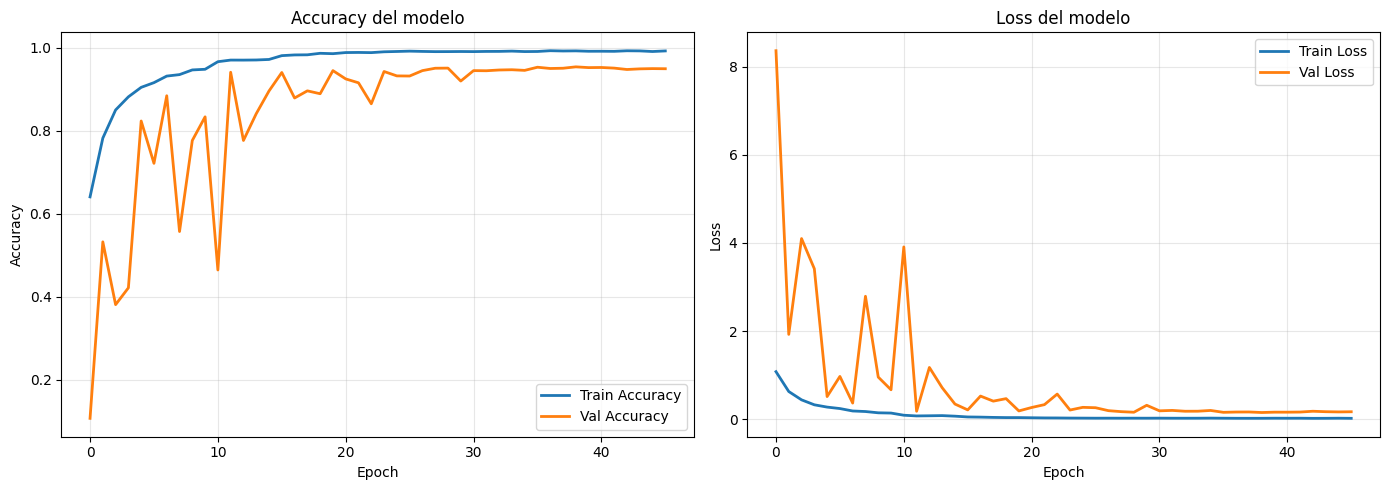

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ── Accuracy ────────────────────────────────────────────────────────────
axes[0].plot(historial_base.history["accuracy"],     label="Train Accuracy",  linewidth=2)
axes[0].plot(historial_base.history["val_accuracy"], label="Val Accuracy",    linewidth=2)
axes[0].set_title("Accuracy del modelo")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# ── Loss ────────────────────────────────────────────────────────────────
axes[1].plot(historial_base.history["loss"],     label="Train Loss",  linewidth=2)
axes[1].plot(historial_base.history["val_loss"], label="Val Loss",    linewidth=2)
axes[1].set_title("Loss del modelo")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


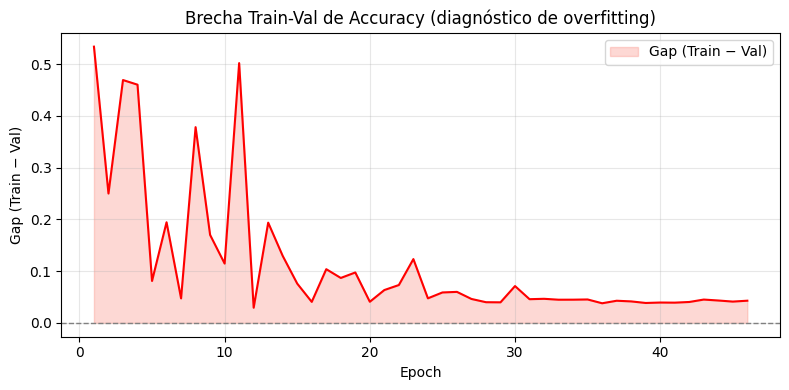


Gap máximo: 0.534  |  Gap final: 0.043
Un gap > 0.10 sostenido indica posible overfitting.


In [33]:
train_acc = np.array(historial_base.history["accuracy"])
val_acc   = np.array(historial_base.history["val_accuracy"])
gap       = train_acc - val_acc
epochs    = np.arange(1, len(gap) + 1)

plt.figure(figsize=(8, 4))
plt.fill_between(epochs, gap, alpha=0.3, color="salmon", label="Gap (Train − Val)")
plt.plot(epochs, gap, color="red", linewidth=1.5)
plt.axhline(0, color="gray", linestyle="--", linewidth=1)
plt.title("Brecha Train-Val de Accuracy (diagnóstico de overfitting)")
plt.xlabel("Epoch")
plt.ylabel("Gap (Train − Val)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"\nGap máximo: {gap.max():.3f}  |  Gap final: {gap[-1]:.3f}")
print("Un gap > 0.10 sostenido indica posible overfitting.")


## 10. Matriz de confusión y reporte de clasificación

Mostramos en qué se equivoca el modelo: tabla con predicciones vs reales, y métricas por cada enfermedad.


Generando predicciones para el conjunto de prueba...
129/129 ━━━━━━━━━━━━━━━━━━━━ 4s 32ms/step


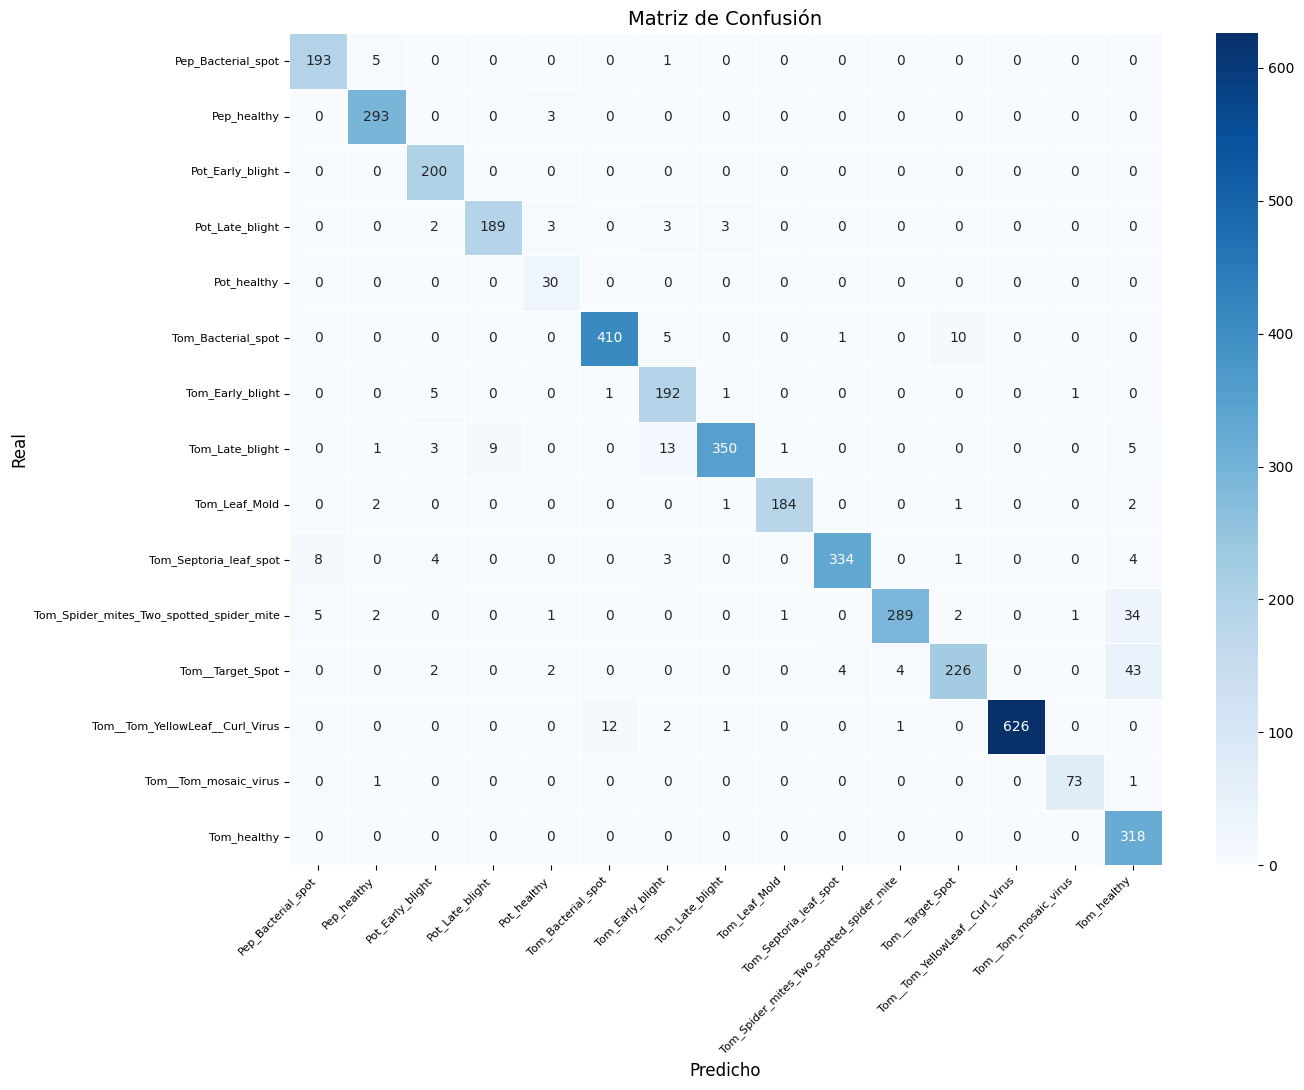


Reporte de Clasificación:
                                             precision    recall  f1-score   support

              Pepper__bell___Bacterial_spot       0.94      0.97      0.95       199
                     Pepper__bell___healthy       0.96      0.99      0.98       296
                      Potato___Early_blight       0.93      1.00      0.96       200
                       Potato___Late_blight       0.95      0.94      0.95       200
                           Potato___healthy       0.77      1.00      0.87        30
                      Tomato_Bacterial_spot       0.97      0.96      0.97       426
                        Tomato_Early_blight       0.88      0.96      0.92       200
                         Tomato_Late_blight       0.98      0.92      0.95       382
                           Tomato_Leaf_Mold       0.99      0.97      0.98       190
                  Tomato_Septoria_leaf_spot       0.99      0.94      0.96       354
Tomato_Spider_mites_Two_spotted_spide

In [34]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# ── nombres de clases en orden alfabético+ ──
nombres_clases = [
    "Pepper__bell___Bacterial_spot",
    "Pepper__bell___healthy",
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
    "Tomato_Bacterial_spot",
    "Tomato_Early_blight",
    "Tomato_Late_blight",
    "Tomato_Leaf_Mold",
    "Tomato_Septoria_leaf_spot",
    "Tomato_Spider_mites_Two_spotted_spider_mite",
    "Tomato__Target_Spot",
    "Tomato__Tomato_YellowLeaf__Curl_Virus",
    "Tomato__Tomato_mosaic_virus",
    "Tomato_healthy"
]

print("Generando predicciones para el conjunto de prueba...")

y_true = np.concatenate([y for x, y in ds_test], axis=0)

# Predicciones
y_pred_probs = modelo_base.predict(ds_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# ── Matriz de confusión ──
cm = confusion_matrix(y_true, y_pred)

nombres_cortos = [n.replace("Tomato_", "Tom_")
                   .replace("Potato___", "Pot_")
                   .replace("Pepper__bell___", "Pep_")
                   for n in nombres_clases]

plt.figure(figsize=(14, 11))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=nombres_cortos,
    yticklabels=nombres_cortos,
    linewidths=0.5
)
plt.title('Matriz de Confusión', fontsize=14)
plt.xlabel('Predicho', fontsize=12)
plt.ylabel('Real', fontsize=12)
plt.xticks(rotation=45, ha='right', fontsize=8)
plt.yticks(rotation=0, fontsize=8)
plt.tight_layout()
plt.show()

# ── Reporte de clasificación ──
print("\nReporte de Clasificación:")
print(classification_report(y_true, y_pred, target_names=nombres_clases))

## 12. Ver fotos que clasificó mal

Visualizar los errores: qué predijo mal y por qué. Ayuda a entender si es porque se parecen las enfermedades o porque la foto es mala.


##Conclusión

El modelo de clasificación de enfermedades foliares de plantas alcanzó una precisión del 95 % en el conjunto de prueba, con un marco AVH de puntuación G1 del mismo porcentaje, lo que indica un rendimiento sólido en las 15 clases.

El entrenamiento tuvo una fase inicial inestable, pero convergió correctamente, finalizando con una diferencia entre los conjuntos de entrenamiento y validación de aproximadamente 0,06. El único punto débil es la clase Tomato__Target_Spot obtiene un valor de 0,80 en esta métrica, lo que indica que en algunos casos se confunde con clases visualmente similares. Sin embargo, en general, el modelo mantiene un desempeño bueno en clasificación.